## Submission & Learning Opportunity: Hill of Towie Wind Turbine Power Prediction

[Kaggle: hill-of-towie-wind-turbine-power-prediction](https://www.kaggle.com/competitions/hill-of-towie-wind-turbine-power-prediction/overview)

| Date        | Score       | Comment                                                              |
| ----------- | ----------- |  ------------------------------------------------------------------  |
| 20250724    | 56.67       | First attempt, HistGradientBoostingRegressor, No Feature Engineering |
| 20250724    | 56.53       | Wind speed estimate using HistGradientBoostingRegressor              |
| 20250724    | 56.29       | Added elapsed seconds,cyclic hour encoding and lagging features      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |

In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kagglehub.config import DEFAULT_CACHE_FOLDER

/Users/joarsolvang/Documents/Github/floris-timeseries/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CACHE_DIR = Path(DEFAULT_CACHE_FOLDER) / "competitions" / "hill-of-towie-wind-turbine-power-prediction"


def load_training_dataset(*, force_download: bool = False) -> pd.DataFrame:
    file_path = kagglehub.competition_download(
        handle="hill-of-towie-wind-turbine-power-prediction",
        path="training_dataset.parquet",
        force_download=force_download,
    )
    return pd.read_parquet(Path(file_path))

In [3]:
complete_data = load_training_dataset()

In [4]:
complete_data

,TimeStamp_StartFormat,wtc_AcWindSp_mean;1,wtc_AcWindSp_mean;2,wtc_AcWindSp_mean;3,wtc_AcWindSp_mean;4,wtc_AcWindSp_mean;5,wtc_AcWindSp_mean;7,wtc_AcWindSp_min;1,wtc_AcWindSp_min;2,wtc_AcWindSp_min;3,...,ERA5_surface_pressure,ERA5_cloud_cover,ERA5_wind_speed_10m,ERA5_wind_speed_100m,ERA5_wind_direction_10m,ERA5_wind_direction_100m,ERA5_wind_gusts_10m,id,is_valid,target
0,2016-01-01 00:00:00+00:00,6.085917,5.830675,6.613091,6.998510,7.645727,7.040790,2.00,1.10,1.60,...,976.166321,0.0,6.080296,10.040418,233.695404,236.784729,13.0,-210384,True,352.522308
1,2016-01-01 00:10:00+00:00,5.824693,5.810768,5.895642,6.521900,6.413868,6.599652,2.10,2.20,1.90,...,982.179504,100.0,3.301515,6.958448,178.264328,187.431320,6.9,-210383,True,294.078888
2,2016-01-01 00:20:00+00:00,7.100180,6.386981,7.606015,7.695034,7.812548,7.469052,2.20,2.10,0.00,...,985.240540,78.0,3.478505,4.648656,198.435043,198.824799,7.7,-210382,True,587.302795
3,2016-01-01 00:30:00+00:00,8.232280,7.787337,7.808475,9.624884,9.727865,8.529939,3.20,2.60,2.10,...,983.532532,82.0,3.400000,6.774216,180.000000,188.488861,6.4,-210381,True,881.533325
4,2016-01-01 00:40:00+00:00,9.534926,8.607587,9.268380,10.105590,9.908615,9.968257,4.60,2.70,5.20,...,976.718750,99.0,3.006659,4.401136,356.186005,358.698059,9.2,-210380,True,1299.646973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210379,2019-12-31 23:10:00+00:00,8.897216,6.674914,8.790455,9.309954,6.749103,9.335896,4.81,3.26,4.40,...,1001.884033,69.0,3.088689,6.236986,209.054504,221.099411,5.6,-5,True,964.380127
210380,2019-12-31 23:20:00+00:00,9.303802,7.503870,8.951791,9.976680,8.194743,8.700228,6.32,3.59,4.98,...,996.454956,95.0,4.326662,8.902246,213.690094,218.157272,8.5,-4,True,1106.759033
210381,2019-12-31 23:30:00+00:00,8.292965,7.242282,7.387715,8.898215,7.778623,7.802809,4.98,4.98,4.49,...,996.174988,55.0,4.701064,9.276314,218.088821,221.941223,8.8,-3,True,687.353088
210382,2019-12-31 23:40:00+00:00,9.617872,9.914719,8.692904,10.193710,10.449450,8.951912,6.63,5.90,5.90,...,1001.884033,69.0,3.088689,6.236986,209.054504,221.099411,5.6,-2,True,1107.057007


In [5]:
t1_columns = [col for col in complete_data.columns if ";1" in col]
complete_data[t1_columns]

,wtc_AcWindSp_mean;1,wtc_AcWindSp_min;1,wtc_AcWindSp_max;1,wtc_AcWindSp_stddev;1,wtc_ScYawPos_mean;1,wtc_ScYawPos_min;1,wtc_ScYawPos_max;1,wtc_ScYawPos_stddev;1,wtc_NacelPos_mean;1,wtc_NacelPos_min;1,...,wtc_PitcPosB_mean;1,wtc_PitcPosC_mean;1,wtc_PowerRef_endvalue;1,wtc_ScReToOp_timeon;1,wtc_ActPower_mean;1,wtc_ActPower_min;1,wtc_ActPower_max;1,wtc_ActPower_stddev;1,wtc_AmbieTmp_mean;1,ShutdownDuration;1
0,6.085917,2.00,10.00,1.484347,83.754387,79.500000,86.800003,2.266932,83.751183,79.500000,...,-0.966370,-0.995090,2300.0,600.0,352.522308,78.0,760.0,187.078903,0.000000,0
1,5.824693,2.10,9.60,1.141584,88.496246,84.400002,91.400002,1.879867,88.491821,84.400002,...,-0.966463,-0.995205,2300.0,600.0,294.078888,119.0,564.0,104.474998,0.000000,0
2,7.100180,2.20,11.60,1.599640,83.129791,81.300003,87.800003,1.907214,83.128883,81.300003,...,-0.963727,-0.986437,2300.0,600.0,587.302795,182.0,1458.0,243.555801,0.000000,0
3,8.232280,3.20,13.30,1.740764,86.001266,84.500000,88.699997,1.195644,86.003304,84.500000,...,-0.964855,-0.985332,2300.0,600.0,881.533325,412.0,1902.0,285.714600,0.000000,0
4,9.534926,4.60,17.40,2.161300,81.587280,76.900002,88.500000,3.047187,81.590797,76.900002,...,-0.897377,-0.927097,2300.0,600.0,1299.646973,437.0,2336.0,531.022827,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210379,8.897216,4.81,12.69,1.453008,-96.119614,-100.699997,-90.599998,3.985432,263.887207,259.299988,...,-0.933015,-0.978328,2300.0,600.0,964.380127,678.0,1406.0,184.697006,3.516783,0
210380,9.303802,6.32,12.21,1.038562,-97.002197,-103.000000,-90.599998,4.699871,262.990387,257.000000,...,-0.933860,-0.977745,2300.0,600.0,1106.759033,703.0,1448.0,177.164505,4.467517,0
210381,8.292965,4.98,10.79,0.972607,-96.173378,-103.000000,-89.900002,3.659225,263.833313,257.000000,...,-0.939138,-0.975448,2300.0,600.0,687.353088,470.0,834.0,76.277786,4.618834,0
210382,9.617872,6.63,12.81,0.957572,-83.940231,-92.199997,-80.000000,3.346503,276.072205,267.899994,...,-0.941788,-0.978313,2300.0,600.0,1107.057007,540.0,1496.0,195.377304,3.230533,0


In [6]:
pc_data = complete_data[["wtc_ActPower_mean;1", "wtc_AcWindSp_mean;1"]]
pc_data = pc_data[pc_data["wtc_ActPower_mean;1"] > 20]
bins = pd.interval_range(start=0, end=25, freq=0.5)
pc_data["wind_speed_bin"] = pd.cut(pc_data["wtc_AcWindSp_mean;1"], bins=bins)
pc_data.dropna(inplace=True)
power_curve = (
    pc_data.groupby("wind_speed_bin", observed=True)
    .agg(
        power_mean=("wtc_ActPower_mean;1", "mean"),
        power_std=("wtc_ActPower_mean;1", "std"),
        power_count=("wtc_ActPower_mean;1", "count"),
    )
    .reset_index()
)

In [7]:
power_curve["bin_mid"] = power_curve["wind_speed_bin"].apply(lambda x: x.mid)
power_curve.loc[power_curve["power_count"] < 500, ["power_mean", "power_count", "power_std"]] = np.nan
power_curve = power_curve.ffill()
power_curve

,wind_speed_bin,power_mean,power_std,power_count,bin_mid
0,"(2.0, 2.5]",NaN,NaN,NaN,2.25
1,"(2.5, 3.0]",29.168882,6.775199,1192.0,2.75
2,"(3.0, 3.5]",38.303844,12.070136,4578.0,3.25
3,"(3.5, 4.0]",58.666476,17.120749,8890.0,3.75
4,"(4.0, 4.5]",91.231813,20.464587,10607.0,4.25
5,"(4.5, 5.0]",132.113599,25.687266,11380.0,4.75
6,"(5.0, 5.5]",183.678032,35.403475,11441.0,5.25
7,"(5.5, 6.0]",251.453159,50.856178,12029.0,5.75
8,"(6.0, 6.5]",340.617334,65.581706,11845.0,6.25
9,"(6.5, 7.0]",448.838800,75.510969,11478.0,6.75


Text(0.5, 0, 'wtc_AcWindSp_mean;1')

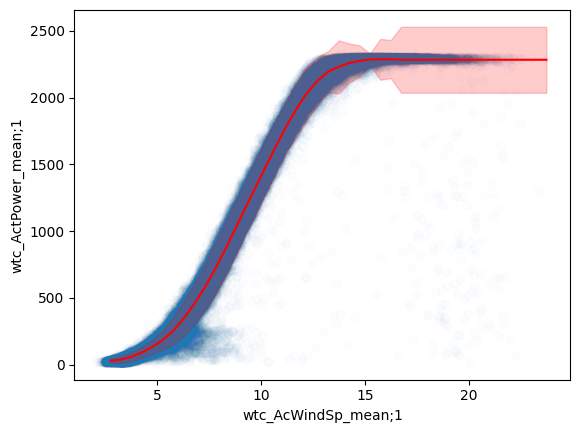

In [8]:
fig, ax = plt.subplots()
ax.scatter(pc_data["wtc_AcWindSp_mean;1"], pc_data["wtc_ActPower_mean;1"], alpha=0.01)
ax.plot(power_curve["bin_mid"], power_curve["power_mean"], color="r")
ax.fill_between(
    power_curve["bin_mid"],
    power_curve["power_mean"] - 2 * power_curve["power_std"],
    power_curve["power_mean"] + 2 * power_curve["power_std"],
    color="r",
    alpha=0.2,
)
ax.set_ylabel("wtc_ActPower_mean;1")
ax.set_xlabel("wtc_AcWindSp_mean;1")